In [3]:
import pandas as pd
import numpy as np
import datatable as dt

In [4]:
phenotype_df = pd.read_csv('/home/student2024/Desktop/Project_Depression/combined_dataset_phenotypes_corrected.csv')
phenotype_df.head()
#phenotype_df.shape

,ID,Sex,Age,Depression,Study,depr_one_hot
0,GSM3562834_3999840035_R01C01,0,73,Control,1,0
1,GSM3562835_3999840035_R01C02,1,32,Case,1,1
2,GSM3562836_3999840035_R02C01,0,51,Case,1,1
3,GSM3562837_3999840035_R02C02,1,30,Case,1,1
4,GSM3562838_3999840035_R03C01,0,53,Case,1,1


In [5]:
methyl_dt = dt.fread('/home/student2024/Desktop/Project_Depression/combined_dataset_methyl.csv')
methyl_dt.head()

,C0,cg18147296,cg13938959,cg12445832,cg23999112,cg11527153,cg04195702,cg23733394,cg13371836,cg04407431,…,cg26034629,cg25232725,cg05615487,cg22122449,cg08423507
,▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪,▪▪▪▪▪▪▪▪
0,GSM3562834_3999840035_R01C01,3.70786,0.351409,−1.35497,0.637529,2.22649,4.34651,−0.36142,−6.08811,−6.65401,…,3.96426,3.14982,3.91352,4.58992,5.13103
1,GSM3562835_3999840035_R01C02,2.04928,0.812738,−1.22874,0.474926,3.03654,2.08212,−1.95944,−5.97729,−5.70413,…,2.75299,2.5356,2.61388,2.84349,4.96877
2,GSM3562836_3999840035_R02C01,3.02593,1.01402,0.133827,1.23557,3.49016,2.8171,−1.14966,−5.84371,−5.99678,…,2.84062,2.79293,2.74396,3.09284,4.80567
3,GSM3562837_3999840035_R02C02,2.74041,0.801563,−0.427657,1.71563,2.56252,3.28615,−1.10128,−6.03164,−5.86204,…,2.71411,2.37371,2.58733,2.71807,4.64723
4,GSM3562838_3999840035_R03C01,1.8795,1.17244,−0.474628,1.3215,2.89588,2.38571,−1.01839,−5.86249,−5.9381,…,2.66998,2.04192,2.88587,3.68936,5.10734
5,GSM3562839_3999840035_R03C02,2.61439,0.4443,−0.512535,1.88327,2.20798,2.44319,−1.00328,−5.80453,−5.91005,…,2.77393,1.88337,2.89875,2.78914,5.07581
6,GSM3562840_3999840035_R04C01,2.21518,1.00344,−1.18175,0.712234,2.76955,2.80845,−1.03108,−6.08054,−5.91474,…,2.77399,2.63257,3.12591,3.1781,5.39504
7,GSM3562841_3999840035_R04C02,2.80365,1.23558,−0.481356,1.64223,2.86825,2.4626,−0.929853,−6.02325,−5.6965,…,2.86204,2.18843,3.07924,2.24435,5.27105
8,GSM3562842_3999840035_R05C01,2.6419,2.78067,−0.558824,1.35189,1.56805,2.5365,−2.20402,−5.97186,−5.92387,…,3.07928,3.66626,2.8359,2.87457,5.16585


In [6]:
methyl_df = methyl_dt.to_pandas()
methyl_df = methyl_df.rename(columns={'C0':'ID'})

In [7]:
combined_df = methyl_df.merge(phenotype_df, how='outer', on='ID')
combined_df.head()


,ID,cg18147296,cg13938959,cg12445832,cg23999112,cg11527153,cg04195702,cg23733394,cg13371836,cg04407431,...,cg26034629,cg25232725,cg05615487,cg22122449,cg08423507,Sex,Age,Depression,Study,depr_one_hot
0,GSM3562834_3999840035_R01C01,3.707855,0.351409,-1.354975,0.637529,2.226487,4.346512,-0.361420,-6.088109,-6.654006,...,3.964259,3.149816,3.913521,4.589916,5.131027,0,73,Control,1,0
1,GSM3562835_3999840035_R01C02,2.049280,0.812738,-1.228742,0.474926,3.036539,2.082123,-1.959440,-5.977291,-5.704133,...,2.752988,2.535602,2.613876,2.843486,4.968767,1,32,Case,1,1
2,GSM3562836_3999840035_R02C01,3.025933,1.014025,0.133827,1.235574,3.490162,2.817102,-1.149658,-5.843710,-5.996775,...,2.840620,2.792934,2.743963,3.092844,4.805671,0,51,Case,1,1
3,GSM3562837_3999840035_R02C02,2.740408,0.801563,-0.427657,1.715626,2.562522,3.286151,-1.101275,-6.031636,-5.862035,...,2.714111,2.373710,2.587334,2.718066,4.647227,1,30,Case,1,1
4,GSM3562838_3999840035_R03C01,1.879498,1.172441,-0.474628,1.321502,2.895880,2.385709,-1.018389,-5.862493,-5.938096,...,2.669980,2.041923,2.885871,3.689359,5.107343,0,53,Case,1,1


In [8]:
from sklearnex import patch_sklearn
patch_sklearn()

Intel(R) Extension for Scikit-learn* enabled (https://github.com/intel/scikit-learn-intelex)


In [9]:
combined_df = combined_df.drop(columns=['ID','Depression'])

In [10]:
from sklearn.model_selection import GroupShuffleSplit 
splitter = GroupShuffleSplit(test_size=.20, n_splits=2, random_state = 7)
split = splitter.split(combined_df, groups=combined_df['Study'])
train_inds, test_inds = next(split)

train = combined_df.iloc[train_inds]
test = combined_df.iloc[test_inds]

In [11]:
x_train = train.drop(columns=['Study','depr_one_hot'])
x_test = test.drop(columns=['Study','depr_one_hot'])
y_train = train['depr_one_hot']
y_test = test['depr_one_hot']

In [12]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    bootstrap = True,
    ccp_alpha = 0.0,
    class_weight = None,
    criterion= 'gini',
    maxBins = 256,
    max_depth = None,
    max_features = 'sqrt',
    max_leaf_nodes = None,
    max_samples = None,
    minBinSize = 1,
    min_impurity_decrease = 0.0,
    min_samples_leaf = 1,
    min_samples_split = 2,
    min_weight_fraction_leaf = 0.0,
    n_estimators = 100,
    n_jobs = None,
    oob_score = False,
    random_state = 22,
    verbose = 0,
    warm_start = False)
#parameters obtained from hyperparameter tuning

rf.fit(x_train,y_train)

RandomForestClassifier(random_state=22)

In [13]:
y_pred = rf.predict(x_test)

In [14]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7725752508361204


In [15]:
from sklearn.metrics import classification_report
print(classification_report(y_pred, y_test))

              precision    recall  f1-score   support

           0       0.53      0.59      0.56        73
           1       0.86      0.83      0.85       226

    accuracy                           0.77       299
   macro avg       0.70      0.71      0.70       299
weighted avg       0.78      0.77      0.78       299



In [16]:
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print('TN = ',tn,'\nFP = ',fp,'\nFN = ',fn,'\nTP = ',tp)

TN =  43 
FP =  38 
FN =  30 
TP =  188


In [17]:
from sklearn.metrics import roc_auc_score
print(roc_auc_score(y_pred, y_test))


0.7104497514850285


In [19]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, threshold = roc_curve(y_test, y_pred)
roc_auc = auc(fpr, tpr)

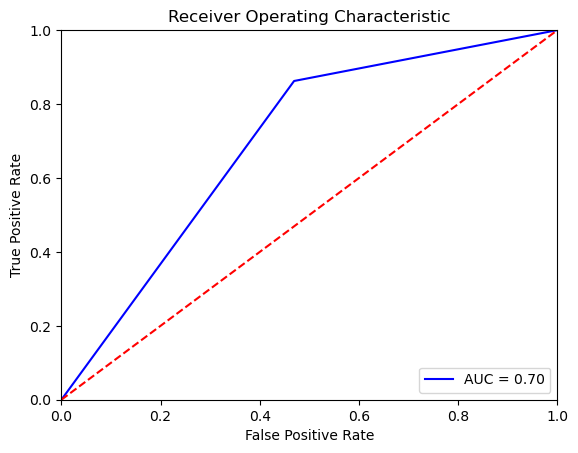

In [20]:
import matplotlib.pyplot as plt
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [21]:
column_names = list(combined_df.columns.values)
print(column_names)

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



In [22]:
#print(rf.feature_importances_)
important_features = rf.feature_importances_
#type(important_features)
rf_feature_importance_df = pd.DataFrame([x_test.columns.tolist(), important_features.tolist()]).T
rf_feature_importance_df.columns = ['column_name', 'rf_feature_importance']
rf_feature_importance_df = rf_feature_importance_df.sort_values('rf_feature_importance', ascending=False)
rf_feature_importance_df

,column_name,rf_feature_importance
117023,cg02247356,0.000781
188604,cg00704953,0.000733
235931,cg06572974,0.000701
184357,cg10659216,0.000685
246504,cg06993715,0.000681
...,...,...
103187,cg07180523,0.0
103186,cg11081826,0.0
103185,cg04949608,0.0
103184,cg14538051,0.0


In [23]:
rf_feature_importance_df.to_csv('random forest feature importance.csv')

In [24]:
import shap
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(x_test)

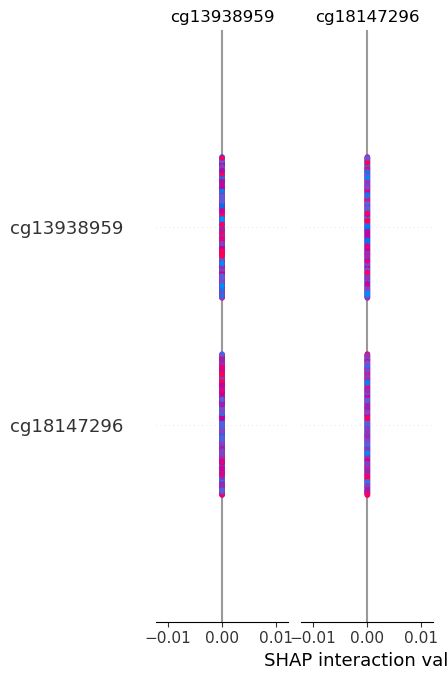

In [25]:
shap.summary_plot(shap_values, x_test)

In [26]:
shap_sum = np.abs(shap_values).mean(axis=0)
importance_df = pd.DataFrame([x_test.columns.tolist(), shap_sum.tolist()]).T
importance_df.columns = ['column_name', 'shap_importance']
importance_df = importance_df.sort_values('shap_importance', ascending=False)
importance_df

,column_name,shap_importance
94714,cg03755794,"[0.002586492388998906, 0.0025864923889989057]"
278873,cg19743791,"[0.0021787873956540024, 0.0021787873956539386]"
35240,cg02073763,"[0.002134958131263599, 0.0021349581312636]"
88122,cg16405876,"[0.0020813761260598967, 0.002081376126059896]"
279363,cg03417156,"[0.0019094446483886327, 0.0019094446483886296]"
...,...,...
103187,cg07180523,"[0.0, 0.0]"
103186,cg11081826,"[0.0, 0.0]"
103185,cg04949608,"[0.0, 0.0]"
103184,cg14538051,"[0.0, 0.0]"


In [64]:
#importance_df.to_csv('shap importance.csv')

In [27]:
top_rf_imp = rf_feature_importance_df[:1000]
top_rf_imp = top_rf_imp['column_name'].tolist()
print(top_rf_imp)
top_shap_imp = importance_df[:1000]
top_shap_imp = top_shap_imp['column_name'].tolist()
print(top_shap_imp)

['cg02247356', 'cg00704953', 'cg06572974', 'cg10659216', 'cg06993715', 'cg11441693', 'cg11509088', 'cg21703606', 'cg03022368', 'cg13256993', 'cg00371239', 'cg02824604', 'cg21047196', 'cg06157318', 'cg04203901', 'cg01008004', 'cg02336491', 'cg16189722', 'cg25131922', 'cg02504541', 'cg04314555', 'cg06012215', 'cg02583309', 'cg20724073', 'cg05530751', 'cg12232308', 'cg10737883', 'cg23228694', 'cg15704369', 'cg02610507', 'cg05670865', 'cg00373247', 'cg20739912', 'cg14636922', 'cg24409107', 'cg06114456', 'cg22899163', 'cg09425356', 'cg27569300', 'cg17769463', 'cg19469449', 'cg22077997', 'cg26259610', 'cg09435824', 'cg14454397', 'cg08790487', 'cg25132878', 'cg23636419', 'cg10135520', 'cg01972751', 'cg09864990', 'cg03536983', 'cg03131732', 'cg13917004', 'cg13620770', 'cg24266227', 'cg06671706', 'cg14310034', 'cg20146873', 'cg00661777', 'cg03755794', 'cg19716816', 'cg25644380', 'cg24652956', 'cg14602839', 'cg06157219', 'cg23481862', 'cg08685384', 'cg00996315', 'cg15385386', 'cg10485664', 'cg19

In [28]:
imp_sites = [i for i in top_rf_imp if i in top_shap_imp]
print(len(imp_sites))

368


In [29]:
print(imp_sites)

['cg02247356', 'cg00704953', 'cg06572974', 'cg10659216', 'cg06993715', 'cg11441693', 'cg11509088', 'cg21703606', 'cg03022368', 'cg13256993', 'cg00371239', 'cg02824604', 'cg21047196', 'cg06157318', 'cg04203901', 'cg01008004', 'cg02336491', 'cg16189722', 'cg25131922', 'cg02504541', 'cg04314555', 'cg06012215', 'cg02583309', 'cg20724073', 'cg05530751', 'cg12232308', 'cg10737883', 'cg23228694', 'cg15704369', 'cg02610507', 'cg05670865', 'cg00373247', 'cg20739912', 'cg14636922', 'cg24409107', 'cg06114456', 'cg22899163', 'cg09425356', 'cg27569300', 'cg17769463', 'cg22077997', 'cg26259610', 'cg09435824', 'cg14454397', 'cg08790487', 'cg25132878', 'cg23636419', 'cg10135520', 'cg01972751', 'cg09864990', 'cg03536983', 'cg03131732', 'cg13917004', 'cg13620770', 'cg24266227', 'cg06671706', 'cg14310034', 'cg00661777', 'cg03755794', 'cg19716816', 'cg24652956', 'cg14602839', 'cg06157219', 'cg23481862', 'cg08685384', 'cg00996315', 'cg15385386', 'cg10485664', 'cg19816938', 'cg02061431', 'cg06604102', 'cg26

In [45]:
imp_sites_df = pd.DataFrame(imp_sites)
#imp_sites_df.to_csv('important features common.csv')